# Agri Predictive Analytics Model
**Predict district-level crop yield early, and explain the drivers to business users**

Yuva Intern - Junior Data Scientist Internship (Nagpur) - Project track

**Scenario.** A (fictional) Nagpur agritech start-up wants a yield forecast early enough to act on procurement,
rather than reacting after the damage is done. This notebook covers the whole workflow:
data audit -> cleaning -> leakage check -> time-aware split -> feature engineering -> model comparison and tuning
-> business-cost metrics -> explainability (Shapley values, partial dependence) -> actions -> fairness/stability -> one wrong prediction.

**Important data note.** The brief describes ~350,000 records but ships no file, so the raw data here is a seeded
synthetic stand-in built by `src/generate_data.py`. It contains the problems listed in the brief (mixed price units,
missing monsoon rainfall, wrong yield units) plus leakage traps. All results are on that simulated data and show the
*method*; they are not real Vidarbha yield statistics.

**Forecast timing.** The forecast is issued at the **end of week 20** of the agricultural year (week 1 = 1 June, so about
mid-October). Only data from weeks 1-20 plus information from earlier seasons may be used.

In [1]:
import warnings, json, time
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import precision_recall_curve
from sklearn.inspection import partial_dependence, permutation_importance

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW, FIG, MODELS, REPORTS = ROOT / "data/raw/agri_raw.csv.gz", ROOT / "reports/figures", ROOT / "models", ROOT / "reports"
for p in (FIG, MODELS, REPORTS, ROOT / "data/processed"):
    p.mkdir(parents=True, exist_ok=True)

SEED, CUTOFF = 42, 20
rng = np.random.default_rng(SEED)
RES = {}                       # numbers collected for the report / deck
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
PAL = {"Soybean": "#d97706", "Cotton": "#2563eb", "Tur": "#9333ea", "Rice": "#059669", "Wheat": "#b45309", "Gram": "#dc2626"}
print("root:", ROOT)

root: /home/claude/agri-yield


## 1. Raw data audit
One row = block x crop x week of the agricultural year. First, look at what we were given before touching anything.

In [2]:
raw = pd.read_csv(RAW)
RES["raw_rows"], RES["raw_cols"] = int(len(raw)), int(raw.shape[1])
print(f"rows={len(raw):,}  cols={raw.shape[1]}  years={raw.ag_year.min()}-{raw.ag_year.max()}")
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing_%": (raw.isna().mean() * 100).round(2), "n_unique": raw.nunique()})
print(audit.to_string())
print("\nexact duplicate rows:", int(raw.duplicated().sum()))
print("crop labels   :", sorted(raw.crop.unique()))
print("district labels:", sorted(raw.district.unique()))
print("yield units   :", raw.yield_unit.value_counts().to_dict())
print("rainfall <0   :", int((raw.rainfall_mm < 0).sum()), "rows (sentinel values)")

rows=349,959  cols=23  years=2003-2025
                              dtype  missing_%  n_unique
record_id                     int64       0.00    344448
week_start_date                 str       0.00      1196
ag_year                       int64       0.00        23
week_no                       int64       0.00        52
district                        str       0.00        24
block                           str       0.00        48
mandi_name                      str       0.00        48
crop                            str       0.00        19
seed_variety                    str       0.00       240
area_ha                     float64       0.00      3121
rainfall_mm                 float64       5.11      2743
temp_max_c                  float64       0.00       239
soil_ph                     float64       9.24       188
soil_n_kg_ha                float64       9.78       958
soil_p_kg_ha                float64       9.15       681
soil_k_kg_ha                float64       8.16   

**What the audit shows (and what I will fix):**
- exact duplicate rows, inconsistent labels (`Soya bean`, `Paddy`, `NAGPUR `), `-999` sentinel rainfall;
- rainfall missing mostly in the monsoon weeks (the brief's issue);
- `mandi_price` mixes per-quintal and per-kg values (min price ~0.1 vs median ~2,300);
- `yield_value` mixes q/ha, kg/acre and t/ha, and some rows are mislabelled;
- columns such as `production_tonnes`, `procured_qty_tonnes`, `crop_cutting_estimate_q_ha` only exist **after harvest** (leakage candidates).

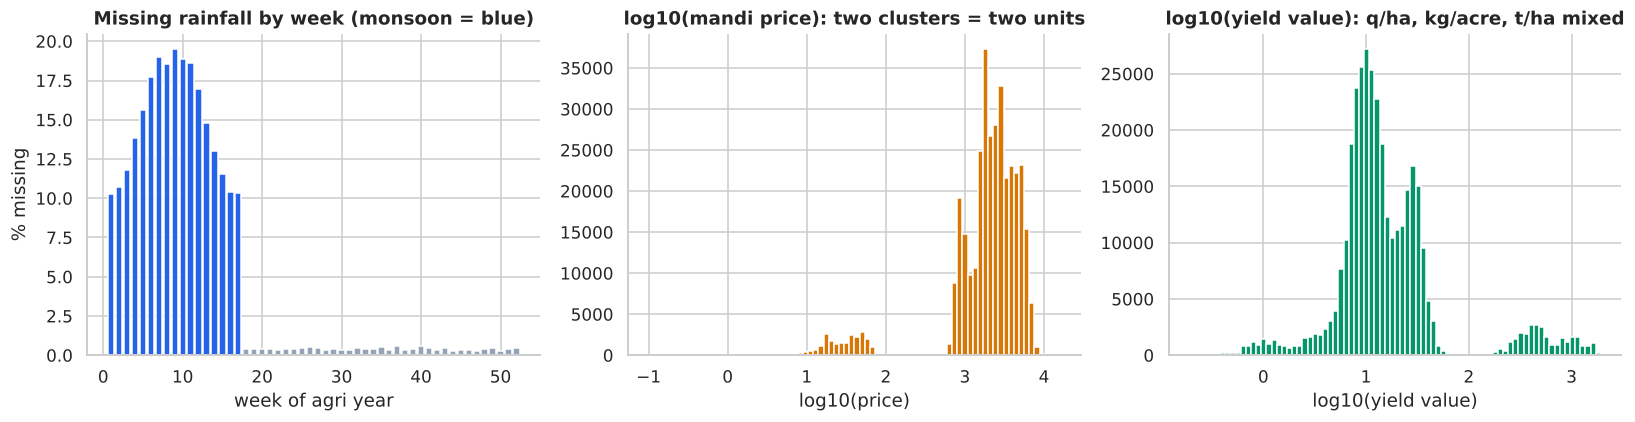

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
m = raw.assign(mon=raw.week_no <= 17).groupby("week_no").rainfall_mm.apply(lambda s: s.isna().mean() * 100)
ax[0].bar(m.index, m.values, color=["#2563eb" if w <= 17 else "#94a3b8" for w in m.index])
ax[0].set(title="Missing rainfall by week (monsoon = blue)", xlabel="week of agri year", ylabel="% missing")
ax[1].hist(np.log10(raw.mandi_price.clip(lower=0.05)), bins=80, color="#d97706")
ax[1].set(title="log10(mandi price): two clusters = two units", xlabel="log10(price)")
ax[2].hist(np.log10(raw.yield_value.dropna().clip(lower=0.05)), bins=80, color="#059669")
ax[2].set(title="log10(yield value): q/ha, kg/acre, t/ha mixed", xlabel="log10(yield value)")
plt.tight_layout(); plt.savefig(FIG / "01_raw_audit.png", dpi=130)

## 2. Cleaning
Each fix is detected from the data itself (not hard-coded), and the number of affected rows is logged.

In [4]:
CLEAN = {}
df = raw.drop_duplicates().copy()
CLEAN["duplicates_removed"] = int(len(raw) - len(df))

# 2a. labels
crop_map = {"soybean": "Soybean", "soya bean": "Soybean", "cotton": "Cotton", "tur": "Tur", "arhar/tur": "Tur",
            "rice": "Rice", "paddy": "Rice", "wheat": "Wheat", "gram": "Gram", "chana": "Gram"}
CLEAN["crop_labels_fixed"] = int((~df.crop.isin(["Soybean", "Cotton", "Tur", "Rice", "Wheat", "Gram"])).sum())
df["crop"] = df.crop.str.strip().str.lower().map(crop_map)
CLEAN["district_labels_fixed"] = int((~df.district.isin(["Nagpur", "Wardha", "Amravati", "Yavatmal", "Chandrapur", "Bhandara"])).sum())
df["district"] = df.district.str.strip().str.title()
assert df.crop.notna().all()

# 2b. mandi price: per-kg entries are ~1/100 of the same crop's price in the same week at other mandis
ref = df.groupby(["crop", "ag_year", "week_no"]).mandi_price.transform("median")
ratio = df.mandi_price / ref
per_kg = ratio < 0.05
CLEAN["price_per_kg_rows"] = int(per_kg.sum())
df["price_qtl"] = np.where(per_kg, df.mandi_price * 100, df.mandi_price)
print("price ratio to peer median  - suspected per-kg rows:", f"{per_kg.sum():,} ({per_kg.mean():.1%})",
      "| median ratio of those rows:", round(float(ratio[per_kg].median()), 4))

# 2c. yield: convert declared units to q/ha, then catch mislabelled values by magnitude
conv = {"q/ha": 1.0, "kg/acre": 1 / 40.47, "t/ha": 10.0}
df["yield_qha"] = df.yield_value * df.yield_unit.map(conv)
cmed = df.groupby("crop").yield_qha.transform("median")
mis = df.yield_qha > 5 * cmed
CLEAN["yield_unit_converted_rows"] = int((df.yield_unit != "q/ha").sum())
CLEAN["yield_mislabelled_rows"] = int(mis.sum())
df.loc[mis, "yield_qha"] = df.loc[mis, "yield_qha"] / 40.47
print("yield rows converted from kg/acre or t/ha:", f"{CLEAN['yield_unit_converted_rows']:,}", "| mislabelled rows fixed by magnitude:", f"{CLEAN['yield_mislabelled_rows']:,}")

# 2d. rainfall: sentinel -> NaN, then impute. Missingness is heaviest in heavy-rain weeks (MNAR), so a global mean would bias totals DOWN.
df.loc[df.rainfall_mm < 0, "rainfall_mm"] = np.nan
df["rain_was_missing"] = df.rainfall_mm.isna().astype(int)
CLEAN["rain_missing_rows"] = int(df.rain_was_missing.sum())
# (i) same block-week reported under another crop (same gauge), (ii) other blocks in the same district-week, (iii) district-week median
r = df.rainfall_mm.fillna(df.groupby(["block", "ag_year", "week_no"]).rainfall_mm.transform("mean"))
r = r.fillna(df.assign(r=r).groupby(["district", "ag_year", "week_no"]).r.transform("mean"))
r = r.fillna(df.assign(r=r).groupby(["district", "week_no"]).r.transform("median")).fillna(0.0)
df["rain"] = r
mm = df[(df.rain_was_missing == 1) & (df.week_no <= 17)]
print(f"imputed monsoon rainfall: mean of imputed cells = {mm.rain.mean():.1f} mm/week vs observed-cell mean = "
      f"{df[(df.rain_was_missing == 0) & (df.week_no <= 17)].rain.mean():.1f}  (heavier weeks go missing more often)")
print(json.dumps(CLEAN, indent=1))
RES["cleaning"] = CLEAN

price ratio to peer median  - suspected per-kg rows: 22,372 (6.5%) | median ratio of those rows: 0.0101
yield rows converted from kg/acre or t/ha: 37,336 | mislabelled rows fixed by magnitude: 2,964
imputed monsoon rainfall: mean of imputed cells = 78.8 mm/week vs observed-cell mean = 58.4  (heavier weeks go missing more often)
{
 "duplicates_removed": 5511,
 "crop_labels_fixed": 10327,
 "district_labels_fixed": 10231,
 "price_per_kg_rows": 22372,
 "yield_unit_converted_rows": 37336,
 "yield_mislabelled_rows": 2964,
 "rain_missing_rows": 18311
}


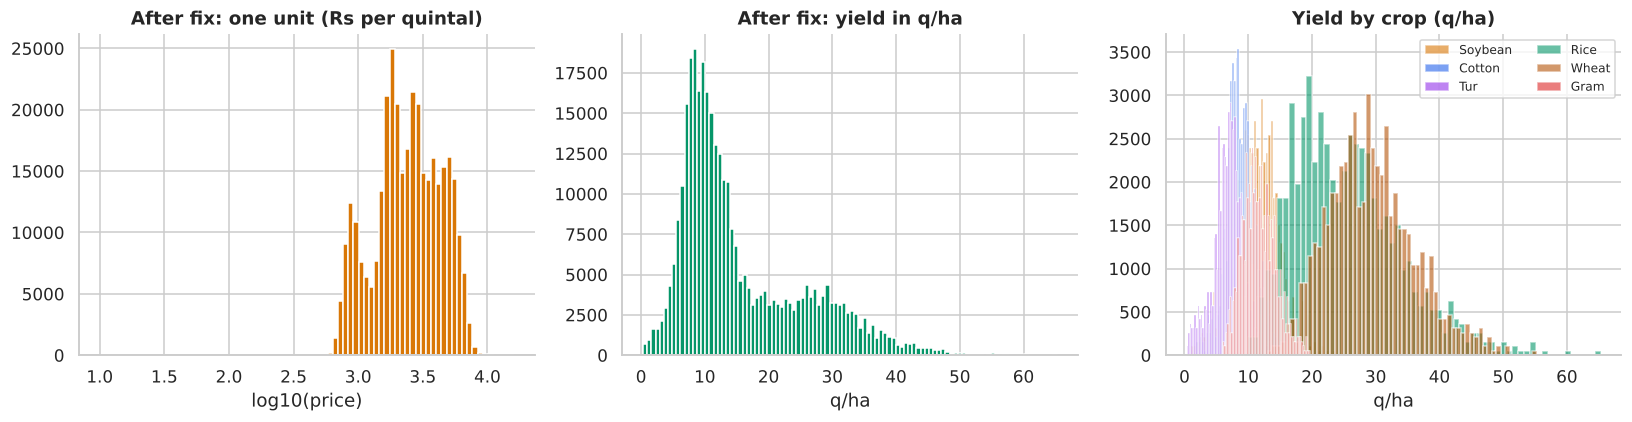

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(np.log10(df.price_qtl), bins=80, color="#d97706"); ax[0].set(title="After fix: one unit (Rs per quintal)", xlabel="log10(price)")
ax[1].hist(df.yield_qha.dropna(), bins=100, color="#059669"); ax[1].set(title="After fix: yield in q/ha", xlabel="q/ha")
for c in PAL:
    ax[2].hist(df[df.crop == c].yield_qha.dropna(), bins=60, alpha=.6, label=c, color=PAL[c])
ax[2].legend(ncol=2, fontsize=8); ax[2].set(title="Yield by crop (q/ha)", xlabel="q/ha")
plt.tight_layout(); plt.savefig(FIG / "02_after_cleaning.png", dpi=130)

## 3. Exploratory analysis
One season record per block x crop x year, built from the weekly rows. Key questions: trend, weather sensitivity, regional
differences, and whether anything looks too good to be true.

season records: 6624 | with yield: 6569


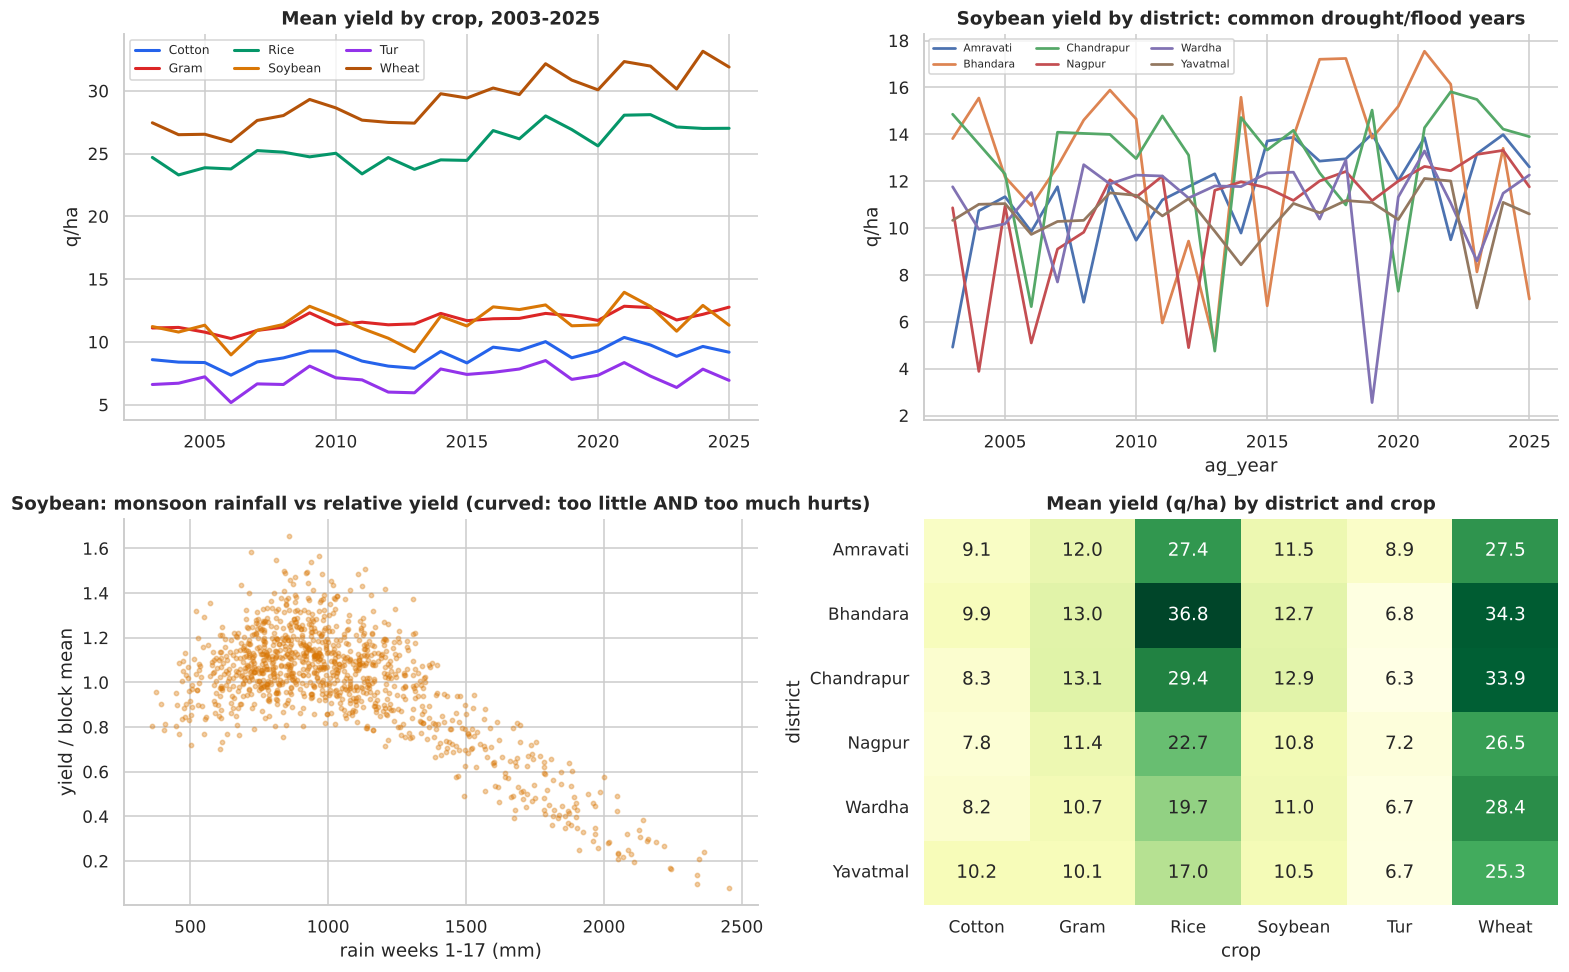

In [6]:
KEYS = ["district", "block", "crop", "ag_year"]
HARV = {"Soybean": 18, "Cotton": 28, "Tur": 32, "Rice": 20, "Wheat": 40, "Gram": 38}   # typical harvest week (agronomy calendar)
df["harvest_wk"] = df.crop.map(HARV)
df["post_harvest"] = df.week_no > df.harvest_wk

season = (df.groupby(KEYS).agg(yield_qha=("yield_qha", "first"), area_ha=("area_ha", "first"), seed_variety=("seed_variety", "first"),
                               mandi_name=("mandi_name", "first"),
                               rain_season_total=("rain", "sum"), cce=("crop_cutting_estimate_q_ha", "first"),
                               production_t=("production_tonnes", "first"), procured_t=("procured_qty_tonnes", "first"))
          .reset_index())
season["rain_mon_full"] = df[df.week_no <= 17].groupby(KEYS).rain.sum().values
season["price_post_harvest"] = df[df.post_harvest].groupby(KEYS).price_qtl.mean().values
season = season.sort_values(["block", "crop", "ag_year"]).reset_index(drop=True)
print("season records:", len(season), "| with yield:", int(season.yield_qha.notna().sum()))

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
tr = season.groupby(["ag_year", "crop"]).yield_qha.mean().unstack()
for c in tr: ax[0, 0].plot(tr.index, tr[c], label=c, color=PAL[c], lw=2)
ax[0, 0].set(title="Mean yield by crop, 2003-2025", ylabel="q/ha"); ax[0, 0].legend(ncol=3, fontsize=8)
dyr = season[season.crop == "Soybean"].groupby(["ag_year", "district"]).yield_qha.mean().unstack()
dyr.plot(ax=ax[0, 1], lw=1.8); ax[0, 1].set(title="Soybean yield by district: common drought/flood years", ylabel="q/ha"); ax[0, 1].legend(fontsize=7, ncol=3)
sub = season[season.crop == "Soybean"].copy(); sub["rel"] = sub.yield_qha / sub.groupby("block").yield_qha.transform("mean")
ax[1, 0].scatter(sub.rain_mon_full, sub.rel, s=8, alpha=.35, color="#d97706"); ax[1, 0].set(title="Soybean: monsoon rainfall vs relative yield (curved: too little AND too much hurts)", xlabel="rain weeks 1-17 (mm)", ylabel="yield / block mean")
dd = season.groupby(["district", "crop"]).yield_qha.mean().unstack()
sns.heatmap(dd, annot=True, fmt=".1f", cmap="YlGn", ax=ax[1, 1], cbar=False); ax[1, 1].set(title="Mean yield (q/ha) by district and crop")
plt.tight_layout(); plt.savefig(FIG / "03_eda_overview.png", dpi=130)

**Reading the EDA**
- Yields trend up slowly (technology) and share clear **bad years** (2009, 2014-15, 2018) across districts - weather is the main driver.
- Soybean yield vs monsoon rainfall is **inverted-U shaped**, so a plain linear term will under-use rainfall; tree models should do better.
- Districts differ systematically (e.g. Bhandara strong on rice), so district/crop must stay in the model.

## 4. Leakage check (before any feature engineering)
A leaky feature is information that would not exist on the forecast date. Three kinds are present in this data:
1. **post-harvest columns** - production, procurement, crop-cutting estimate (they contain the answer);
2. **post-cutoff weather** - season-total rainfall and weeks after week 20;
3. **post-harvest prices** - prices respond to the realised local supply.
Let me test them instead of just assuming.

In [7]:
chk = season.dropna(subset=["yield_qha"]).copy()
chk["prod_per_ha"] = chk.production_t * 10 / chk.area_ha
chk["proc_per_ha"] = chk.procured_t * 10 / chk.area_ha
chk["dev"] = np.log(chk.yield_qha / chk.groupby(["block", "crop"]).yield_qha.transform("mean"))
for c in ["rain_season_total", "price_post_harvest"]:
    chk[c + "_rel"] = np.log(chk[c] / chk.groupby(["block", "crop"])[c].transform("mean"))
rows = []
for c in ["cce", "prod_per_ha", "proc_per_ha"]:
    rows.append((c, "post-harvest column", chk[[c, "yield_qha"]].corr().iloc[0, 1]))
for c in ["rain_season_total_rel", "price_post_harvest_rel"]:
    rows.append((c, "uses weeks after cutoff / after harvest", chk[[c, "dev"]].corr().iloc[0, 1]))
leak = pd.DataFrame(rows, columns=["column", "why suspicious", "correlation with yield (or yield deviation)"]).round(3)
print(leak.to_string(index=False))
RES["leak_table"] = leak.to_dict("records")
print("\nDecision: all five are EXCLUDED from model features. Only weeks 1-20 and earlier seasons are used.")

                column                          why suspicious  correlation with yield (or yield deviation)
                   cce                     post-harvest column                                        0.998
           prod_per_ha                     post-harvest column                                        1.000
           proc_per_ha                     post-harvest column                                        0.934
 rain_season_total_rel uses weeks after cutoff / after harvest                                       -0.502
price_post_harvest_rel uses weeks after cutoff / after harvest                                       -0.057

Decision: all five are EXCLUDED from model features. Only weeks 1-20 and earlier seasons are used.


## 5. Feature engineering (forecast date = end of week 20)
35+ features from five families. Everything is computed from weeks <= 20 of the current season, or from earlier seasons.
- **Rainfall:** window sums, ratio to the block's own history (expanding, past only), 3-year rolling mean, longest dry spell in weeks 5-14, share of readings that were missing.
- **Temperature:** mean and count of hot weeks in the flowering window.
- **Soil:** forward-filled from the last available test (past only) + missing flag + N:P ratio.
- **Price:** early-season level, volatility, momentum, **ratio to the previous year's early price and previous harvest price**.
- **History (lag / rolling / ratio):** last year's yield, 2 years ago, 3-year rolling mean and std, ratios to the rolling mean, district-level lag.
- **High-cardinality categories** (48 blocks, 48 mandis, 240 seed varieties): mandi is a 1:1 duplicate of block, so it is dropped; block and variety are
  encoded with a **past-only, smoothed target encoding** (never uses the row's own year or the future); crop and district are one-hot.

In [8]:
wk = df[df.week_no <= CUTOFF]
def piv(col):
    return wk.pivot_table(index=KEYS, columns="week_no", values=col, aggfunc="first")
R, T, P = piv("rain"), piv("temp_max_c"), piv("price_qtl")
Rm = wk.pivot_table(index=KEYS, columns="week_no", values="rain_was_missing", aggfunc="first")
F = pd.DataFrame(index=R.index)
F["rain_wk1_4"], F["rain_wk5_8"], F["rain_wk9_12"] = R.loc[:, 1:4].sum(1), R.loc[:, 5:8].sum(1), R.loc[:, 9:12].sum(1)
F["rain_wk13_17"], F["rain_wk18_20"] = R.loc[:, 13:17].sum(1), R.loc[:, 18:20].sum(1)
F["rain_mon"] = R.loc[:, 1:17].sum(1)
B = (R.loc[:, 5:14].to_numpy() < 12); cur = np.zeros(len(B)); best = np.zeros(len(B))
for j in range(B.shape[1]):
    cur = (cur + 1) * B[:, j]; best = np.maximum(best, cur)
F["dry_run_wk5_14"] = best
F["rain_missing_share"] = Rm.loc[:, 1:17].mean(1)
F["temp_mean"] = T.mean(1); F["heat_wk8_14"] = (T.loc[:, 8:14] > 35).sum(1); F["heat_wk1_6"] = (T.loc[:, 1:6] > 40).sum(1)
F["price_mean"] = P.mean(1); F["price_vol"] = P.std(1) / P.mean(1)
F["price_mom"] = P.loc[:, 17:20].mean(1) / P.loc[:, 1:4].mean(1)
for src, dst in [("soil_ph", "soil_ph"), ("soil_n_kg_ha", "soil_n"), ("soil_p_kg_ha", "soil_p"), ("soil_k_kg_ha", "soil_k"), ("soil_oc_pct", "soil_oc")]:
    F[dst] = wk.groupby(KEYS)[src].first()
F = F.reset_index()
S = season.merge(F, on=KEYS, how="left").sort_values(["block", "crop", "ag_year"]).reset_index(drop=True)

g = S.groupby(["block", "crop"], sort=False)
# soil: last known test (past only)
S["soil_missing"] = S[["soil_ph", "soil_n", "soil_p", "soil_k", "soil_oc"]].isna().any(axis=1).astype(int)
for c in ["soil_ph", "soil_n", "soil_p", "soil_k", "soil_oc"]:
    S[c] = S.groupby(["block", "crop"], sort=False)[c].ffill()
S["n_p_ratio"] = S.soil_n / S.soil_p
# history of yield
S["yield_lag1"], S["yield_lag2"] = g.yield_qha.shift(1), g.yield_qha.shift(2)
S["yield_roll3"] = g.yield_qha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
S["yield_roll3_std"] = g.yield_qha.transform(lambda s: s.shift(1).rolling(3, min_periods=2).std())
S["lag1_to_roll3"], S["lag2_to_roll3"] = S.yield_lag1 / S.yield_roll3, S.yield_lag2 / S.yield_roll3
S["dc_lag1_to_roll3"] = S.groupby(["district", "crop", "ag_year"]).lag1_to_roll3.transform("mean")
# rainfall history
S["rain_hist_mean"] = g.rain_mon.transform(lambda s: s.shift(1).expanding().mean())
S["rain_ratio_hist"] = S.rain_mon / S.rain_hist_mean
S["rain_ratio_hist_sq"] = (S.rain_ratio_hist - 1) ** 2
S["rain_roll3"] = g.rain_mon.transform(lambda s: s.shift(1).rolling(3, min_periods=2).mean())
# price history (previous seasons are fully known)
S["price_ratio_prev"] = S.price_mean / g.price_mean.shift(1)
S["price_to_prev_post"] = S.price_mean / g.price_post_harvest.shift(1)
S["area_ratio_prev"] = S.area_ha / g.area_ha.shift(1)

# past-only smoothed target encoding for high-cardinality categoricals
S["lr"] = np.log(S.yield_qha) - S.groupby(["district", "crop", "ag_year"]).yield_qha.transform(lambda s: np.log(s).mean())
S["block_crop"] = S.block + "|" + S.crop
def past_te(frame, col, target="lr", m=10):
    agg = frame.groupby([col, "ag_year"]).agg(s=(target, "sum"), n=(target, "count")).reset_index().sort_values([col, "ag_year"])
    agg["cs"] = agg.groupby(col).s.cumsum() - agg.s
    agg["cn"] = agg.groupby(col).n.cumsum() - agg.n
    agg["te"] = agg.cs / (agg.cn + m)
    return frame.merge(agg[[col, "ag_year", "te"]], on=[col, "ag_year"], how="left").te.values
S["te_block"] = past_te(S, "block_crop", m=5)
S["te_variety"] = past_te(S, "seed_variety", m=20)
S = S.sort_values(["block", "crop", "ag_year"]).reset_index(drop=True)
print("variety levels:", S.seed_variety.nunique(), "| block levels:", S.block.nunique(), "| mandi levels:", S.mandi_name.nunique(), "(1:1 with block ->", S.groupby("block").mandi_name.nunique().max() == 1, ")")

CROPS = ["Soybean", "Cotton", "Tur", "Rice", "Wheat", "Gram"]; DIST = ["Nagpur", "Wardha", "Amravati", "Yavatmal", "Chandrapur", "Bhandara"]
for c in CROPS: S["crop_" + c] = (S.crop == c).astype(int)
for d in DIST: S["dist_" + d] = (S.district == d).astype(int)
NUM = ["rain_wk1_4", "rain_wk5_8", "rain_wk9_12", "rain_wk13_17", "rain_wk18_20", "rain_mon", "rain_ratio_hist", "rain_ratio_hist_sq", "rain_roll3",
       "dry_run_wk5_14", "rain_missing_share", "temp_mean", "heat_wk8_14", "heat_wk1_6",
       "soil_ph", "soil_n", "soil_p", "soil_k", "soil_oc", "soil_missing", "n_p_ratio",
       "price_mean", "price_vol", "price_mom", "price_ratio_prev", "price_to_prev_post", "area_ha", "area_ratio_prev",
       "yield_lag1", "yield_lag2", "yield_roll3", "yield_roll3_std", "lag1_to_roll3", "lag2_to_roll3", "dc_lag1_to_roll3",
       "ag_year", "te_block", "te_variety"]
FEATS = NUM + ["crop_" + c for c in CROPS] + ["dist_" + d for d in DIST]
LEAKY = ["rain_season_total", "cce", "production_t", "procured_t", "price_post_harvest"]
assert not set(FEATS) & set(LEAKY)
LRR = [f for f in NUM if "lag" in f or "roll" in f or "ratio" in f or "_to_" in f or "mom" in f]
RES["n_features"], RES["n_engineered"] = len(FEATS), len(LRR)
print("modelling features:", len(FEATS), "| lag/rolling/ratio features:", len(LRR), LRR)

variety levels: 240 | block levels: 48 | mandi levels: 48 (1:1 with block -> True )
modelling features: 50 | lag/rolling/ratio features: 15 ['rain_ratio_hist', 'rain_ratio_hist_sq', 'rain_roll3', 'n_p_ratio', 'price_mom', 'price_ratio_prev', 'price_to_prev_post', 'area_ratio_prev', 'yield_lag1', 'yield_lag2', 'yield_roll3', 'yield_roll3_std', 'lag1_to_roll3', 'lag2_to_roll3', 'dc_lag1_to_roll3']


## 6. Time-aware split
Random splitting would let the model see other blocks of the **same year** (shared weather) in training, which is a form of leakage.
Instead:
- **Train** 2006-2019 (first three seasons are needed to build history features)
- **Validation** 2020-2022 (model selection)
- **Test** 2023-2025 (touched once, at the end)
The target is the log ratio `log(yield / 3-year block-crop rolling mean)`; predictions are converted back to q/ha.

In [9]:
M = S[(S.ag_year >= 2006) & S.yield_qha.notna() & S.yield_roll3.notna()].copy()
M["y"] = np.log(M.yield_qha / M.yield_roll3)
tr, va, te = M[M.ag_year <= 2019], M[M.ag_year.between(2020, 2022)], M[M.ag_year >= 2023]
print(f"train {len(tr):,} ({tr.ag_year.min()}-{tr.ag_year.max()}) | val {len(va):,} | test {len(te):,}")
RES["split"] = {"train": len(tr), "val": len(va), "test": len(te)}
Xtr, ytr, Xva, yva, Xte, yte = tr[FEATS], tr.y, va[FEATS], va.y, te[FEATS], te.y
folds = [(M.index[(M.ag_year <= a)].intersection(tr.index), M.index[M.ag_year.between(a + 1, a + 2)].intersection(tr.index)) for a in (2013, 2015, 2017)]
folds_pos = [(tr.index.get_indexer(a), tr.index.get_indexer(b)) for a, b in folds]
print("expanding-window CV folds (train years -> validate years): <=2013->2014-15, <=2015->2016-17, <=2017->2018-19")

train 3,998 (2006-2019) | val 857 | test 854
expanding-window CV folds (train years -> validate years): <=2013->2014-15, <=2015->2016-17, <=2017->2018-19


## 7. Metrics that match the business cost
Over-forecasting yield means the start-up under-books supply; under-forecasting means over-booking storage and cash. Both cost money in
proportion to the **size of the miss in quintals**, so the primary metric is **MAE in q/ha**, measured at district x crop x year
(the level the product is used at). Secondary: WAPE, and **recall of shortfall events at >=70% precision** (shortfall = yield below
92% of the district-crop 3-year normal), because a missed shortfall is the costly error.

In [10]:
def to_level(frame, pred_ratio):
    f = frame[["district", "block", "crop", "ag_year", "yield_qha", "yield_roll3", "area_ha"]].copy()
    f["pred"] = f.yield_roll3 * np.exp(np.asarray(pred_ratio))
    return f
def district_level(f):
    dcy = f.groupby(["district", "crop", "ag_year"]).agg(actual=("yield_qha", "mean"), pred=("pred", "mean"), normal=("yield_roll3", "mean")).reset_index()
    return dcy
def mae(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def evaluate(frame, pred_ratio):
    f = to_level(frame, pred_ratio); d = district_level(f)
    return {"MAE_block": mae(f.yield_qha, f.pred), "MAE_district": mae(d.actual, d.pred), "WAPE_district_%": 100 * np.abs(d.actual - d.pred).sum() / d.actual.sum()}
def shortfall_recall(d, score, thr):
    y_true = (d.actual < 0.92 * d.normal).astype(int).values
    flag = score >= thr
    tp = int((flag & (y_true == 1)).sum())
    return (tp / max(1, y_true.sum()), tp / max(1, flag.sum()), int(y_true.sum()))
def best_threshold(d, score, min_prec=0.70):
    y_true = (d.actual < 0.92 * d.normal).astype(int).values
    p, r, t = precision_recall_curve(y_true, score)
    ok = np.where(p[:-1] >= min_prec)[0]
    return float(t[ok[np.argmax(r[ok])]]) if len(ok) else float(np.max(score))

## 8. Models: baseline -> linear -> random forest -> gradient boosting
**Baseline** = the 3-year block-crop rolling mean (what an analyst would do without a model; it predicts a ratio of 1).
Models are compared with the expanding-window CV above, then judged on the untouched validation years.

In [11]:
cands = {
    "Ridge (linear)": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.4, n_jobs=1, random_state=SEED),
    "Gradient boosting (default)": HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_depth=4, random_state=SEED),
}
rows = []
for name, mdl in cands.items():
    cv = []
    for a, b in folds_pos:
        m_ = clone(mdl).fit(Xtr.iloc[a], ytr.iloc[a]); cv.append(mae(ytr.iloc[b], m_.predict(Xtr.iloc[b])))
    rows.append((name, np.mean(cv)))
cv_tab = pd.DataFrame(rows, columns=["model", "CV MAE (log-ratio)"]).set_index("model")
cv_tab.loc["Baseline (3-yr rolling mean)"] = mae(ytr, np.zeros(len(ytr)))
print(cv_tab.round(4).sort_values("CV MAE (log-ratio)").to_string())
RES["cv_table"] = cv_tab.round(4)["CV MAE (log-ratio)"].to_dict()

                              CV MAE (log-ratio)
model                                           
Gradient boosting (default)               0.1194
Random forest                             0.1291
Ridge (linear)                            0.1493
Baseline (3-yr rolling mean)              0.1836


**Tuning the best model.** Gradient boosting is the strongest family in CV, so I tune it with randomised search over the same time-aware folds.

In [12]:
t0 = time.time()
space = {"learning_rate": [0.02, 0.03, 0.05, 0.08], "max_iter": [200, 350, 500], "max_depth": [3, 4, 5, 6], "max_leaf_nodes": [8, 15, 31],
         "min_samples_leaf": [20, 40, 80], "l2_regularization": [0.0, 1.0, 5.0, 10.0], "max_features": [0.5, 0.7, 1.0]}
search = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=SEED), space, n_iter=24, cv=folds_pos,
                            scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=False)
search.fit(Xtr, ytr)
best = search.best_params_
print("best params:", best, "\nbest CV MAE (log-ratio):", round(-search.best_score_, 4), f"| {time.time() - t0:.0f}s")
RES["best_params"] = {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in best.items()}
RES["cv_table"]["Gradient boosting (tuned)"] = round(float(-search.best_score_), 4)
gb = HistGradientBoostingRegressor(random_state=SEED, **best)

best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 350, 'max_features': 0.7, 'max_depth': 4, 'learning_rate': 0.08, 'l2_regularization': 1.0} 
best CV MAE (log-ratio): 0.1193 | 32s


In [13]:
def fit_eval(mdl, name):
    m_ = clone(mdl).fit(Xtr, ytr)
    pv = m_.predict(Xva)
    return m_, pv
rows, val_pred, fitted = [], {}, {}
for name, mdl in {**cands, "Gradient boosting (tuned)": gb}.items():
    m_, pv = fit_eval(mdl, name); fitted[name] = m_; val_pred[name] = pv
    rows.append({"model": name, **evaluate(va, pv)})
base_row = {"model": "Baseline (3-yr rolling mean)", **evaluate(va, np.zeros(len(va)))}
rows.append(base_row)
vt = pd.DataFrame(rows).set_index("model").sort_values("MAE_district")
base_mae = vt.loc["Baseline (3-yr rolling mean)", "MAE_district"]
vt["improvement_vs_baseline_%"] = 100 * (base_mae - vt.MAE_district) / base_mae
print(vt.round(3).to_string())
RES["val_table"] = vt.round(3).reset_index().to_dict("records")

                              MAE_block  MAE_district  WAPE_district_%  improvement_vs_baseline_%
model                                                                                            
Gradient boosting (tuned)         1.623         0.849            5.031                     42.030
Gradient boosting (default)       1.625         0.896            5.306                     38.851
Random forest                     1.693         0.938            5.554                     35.999
Baseline (3-yr rolling mean)      2.106         1.465            8.678                      0.000
Ridge (linear)                    2.146         1.583            9.373                     -8.014


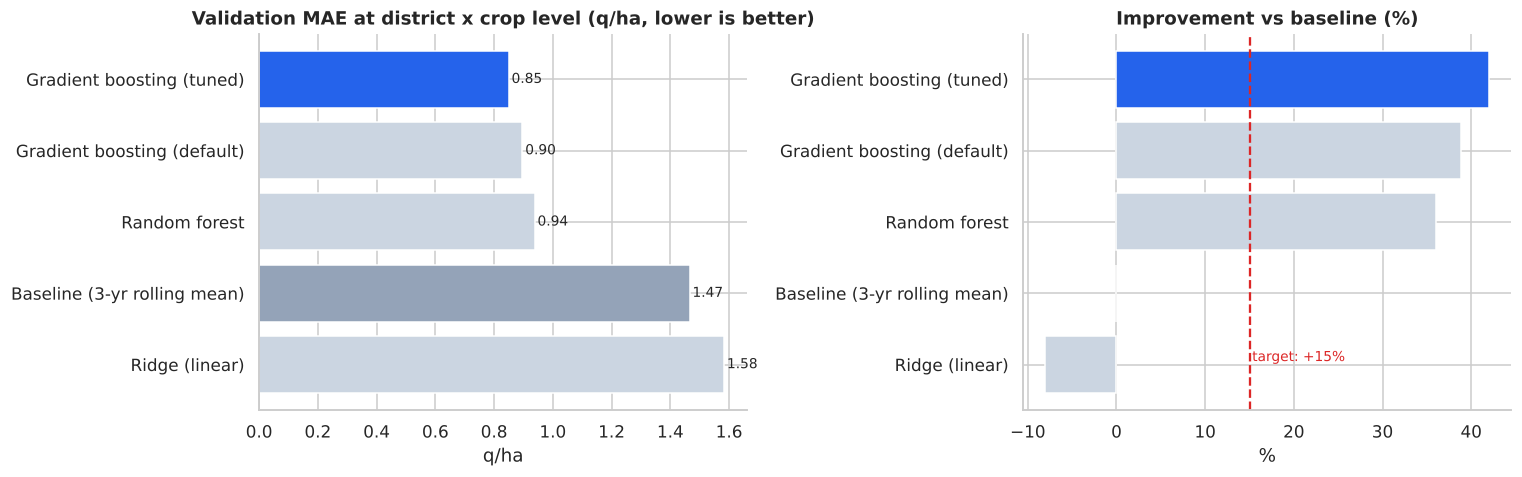

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
o = vt.sort_values("MAE_district", ascending=False)
colors = ["#94a3b8" if "Baseline" in i else "#2563eb" if "tuned" in i else "#cbd5e1" for i in o.index]
ax[0].barh(o.index, o.MAE_district, color=colors); ax[0].set(title="Validation MAE at district x crop level (q/ha, lower is better)", xlabel="q/ha")
for i, v in enumerate(o.MAE_district): ax[0].text(v + .01, i, f"{v:.2f}", va="center", fontsize=9)
ax[1].barh(o.index, o["improvement_vs_baseline_%"], color=colors); ax[1].axvline(15, color="#dc2626", ls="--"); ax[1].text(15.3, 0.05, "target: +15%", color="#dc2626", fontsize=9)
ax[1].set(title="Improvement vs baseline (%)", xlabel="%")
plt.tight_layout(); plt.savefig(FIG / "04_model_comparison.png", dpi=130)

## 9. Final model: refit on train+validation, score once on the test years
Success criteria from the brief:
1. final model beats the baseline by **>= 15%** on the agreed metric;
2. test performance is **within 5%** of validation performance;
3. the top-5 drivers make business sense (section 11).

In [15]:
TV = M[M.ag_year <= 2022]
final = clone(gb).fit(TV[FEATS], TV.y)
pt = final.predict(Xte)
ev_test, ev_base = evaluate(te, pt), evaluate(te, np.zeros(len(te)))
ev_val = evaluate(va, val_pred["Gradient boosting (tuned)"]); ev_val_base = base_row
imp_val = 100 * (ev_val_base["MAE_district"] - ev_val["MAE_district"]) / ev_val_base["MAE_district"]
imp_test = 100 * (ev_base["MAE_district"] - ev_test["MAE_district"]) / ev_base["MAE_district"]
gap = 100 * (ev_test["MAE_district"] - ev_val["MAE_district"]) / ev_val["MAE_district"]
print(f"VALIDATION  model MAE_district {ev_val['MAE_district']:.3f} vs baseline {ev_val_base['MAE_district']:.3f} -> {imp_val:.1f}% better")
print(f"TEST        model MAE_district {ev_test['MAE_district']:.3f} vs baseline {ev_base['MAE_district']:.3f} -> {imp_test:.1f}% better")
print(f"test vs validation MAE gap: {gap:+.1f}%   (criterion: within 5%)")
# also the relative error, which is scale-free and fairer when yields grow over time
print(f"WAPE district-level: validation {ev_val['WAPE_district_%']:.2f}% | test {ev_test['WAPE_district_%']:.2f}%  (gap {ev_test['WAPE_district_%'] - ev_val['WAPE_district_%']:+.2f} pts)")
print("\n--- success criteria from the brief ---")
print(f"1. beat baseline by >=15%  : {'MET' if min(imp_val, imp_test) >= 15 else 'NOT MET'} (validation {imp_val:.1f}%, test {imp_test:.1f}%)")
print(f"2. test within 5% of valid.: {'MET' if abs(gap) <= 5 else 'NOT MET'} (test MAE is {gap:+.1f}% vs validation; the baseline itself got {100*(ev_base['MAE_district']/ev_val_base['MAE_district']-1):+.1f}% worse, so the test years are harder)")
RES["final"] = {"val": ev_val, "test": ev_test, "val_base": {k: v for k, v in ev_val_base.items() if k != "model"}, "test_base": ev_base,
                "imp_val": imp_val, "imp_test": imp_test, "gap_test_vs_val_pct": gap}

dv, dt = district_level(to_level(va, val_pred["Gradient boosting (tuned)"])), district_level(to_level(te, pt))
thr = best_threshold(dv, -np.log(dv.pred / dv.normal))
rv, pv_, nv = shortfall_recall(dv, -np.log(dv.pred / dv.normal), thr)
rt, pt_, nt = shortfall_recall(dt, -np.log(dt.pred / dt.normal), thr)
print(f"\nShortfall events: validation recall {rv:.0%} at precision {pv_:.0%} (n={nv}); test recall {rt:.0%} at precision {pt_:.0%} (n={nt}); threshold fixed on validation")
RES["shortfall"] = {"val_recall": rv, "val_precision": pv_, "val_n": nv, "test_recall": rt, "test_precision": pt_, "test_n": nt}

VALIDATION  model MAE_district 0.849 vs baseline 1.465 -> 42.0% better
TEST        model MAE_district 1.187 vs baseline 1.721 -> 31.0% better
test vs validation MAE gap: +39.8%   (criterion: within 5%)
WAPE district-level: validation 5.03% | test 7.20%  (gap +2.17 pts)

--- success criteria from the brief ---
1. beat baseline by >=15%  : MET (validation 42.0%, test 31.0%)
2. test within 5% of valid.: NOT MET (test MAE is +39.8% vs validation; the baseline itself got +17.5% worse, so the test years are harder)

Shortfall events: validation recall 61% at precision 73% (n=18); test recall 82% at precision 61% (n=28); threshold fixed on validation


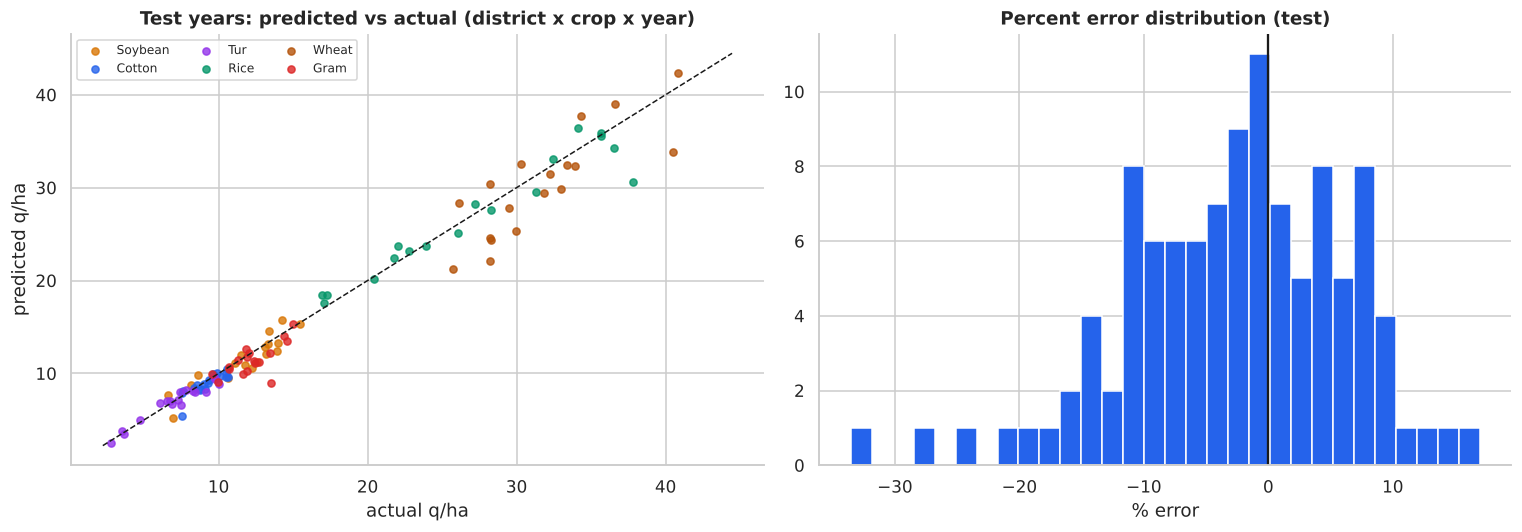

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c in CROPS:
    s = dt[dt.crop == c]; ax[0].scatter(s.actual, s.pred, s=22, alpha=.8, color=PAL[c], label=c)
lim = [dt[["actual", "pred"]].min().min() * .9, dt[["actual", "pred"]].max().max() * 1.05]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(title="Test years: predicted vs actual (district x crop x year)", xlabel="actual q/ha", ylabel="predicted q/ha"); ax[0].legend(ncol=3, fontsize=8)
e = dt.assign(err=dt.pred - dt.actual, rel=(dt.pred / dt.actual - 1) * 100)
ax[1].hist(e.rel, bins=30, color="#2563eb"); ax[1].axvline(0, color="k"); ax[1].set(title="Percent error distribution (test)", xlabel="% error")
plt.tight_layout(); plt.savefig(FIG / "05_test_performance.png", dpi=130)

## 9b. Why is test error higher than validation? (diagnosis, not tuning)
Criterion 2 is not met, so I look for the cause instead of hiding it. EDA showed yield is very sensitive to monsoon rainfall, so the natural suspect is **seasons that
are unusually wet relative to the block's own history** (`rain_ratio_hist` > 1.4): these are rare in training, so the model has few examples to learn them from.

In [17]:
def seg(fr, p):
    t_ = fr.assign(pred=fr.yield_roll3 * np.exp(p)); t_["abs_err"] = (t_.pred - t_.yield_qha).abs(); t_["pct_err"] = 100 * t_.abs_err / t_.yield_qha
    t_["bias_pct"] = 100 * np.log(t_.pred / t_.yield_qha); t_["wet"] = np.where(t_.rain_ratio_hist > 1.4, "unusually wet (>1.4x own history)", "normal or dry")
    t_["season"] = np.where(t_.crop.isin(["Wheat", "Gram"]), "rabi", "kharif"); return t_
tv_ = seg(va, val_pred["Gradient boosting (tuned)"]); tt = seg(te, pt)
for nm, t_ in [("VALIDATION 2020-22", tv_), ("TEST 2023-25", tt)]:
    print(nm, "\n", t_.groupby("wet").agg(rows=("abs_err", "size"), MAPE_pct=("pct_err", "mean"), bias_pct=("bias_pct", "mean")).round(1).to_string(), "\n")
wet_t = tt[tt.wet.str.startswith("unusually")]
print("Test, unusually wet seasons by district:\n", wet_t.groupby("district").agg(rows=("abs_err", "size"), MAPE_pct=("pct_err", "mean"), bias_pct=("bias_pct", "mean")).round(1).to_string())
print("\nTest, unusually wet seasons by crop season:\n", wet_t.groupby("season").agg(rows=("abs_err", "size"), MAPE_pct=("pct_err", "mean"), bias_pct=("bias_pct", "mean")).round(1).to_string())
RES["range_diag"] = {"wet_share_val": float((tv_.wet.str.startswith("unusually")).mean()), "wet_share_test": float((tt.wet.str.startswith("unusually")).mean()),
    "mape_normal_val": float(tv_[~tv_.wet.str.startswith("unusually")].pct_err.mean()), "mape_normal_test": float(tt[~tt.wet.str.startswith("unusually")].pct_err.mean()),
    "mape_wet_test": float(wet_t.pct_err.mean()), "bias_wet_test": float(wet_t.bias_pct.mean()),
    "bhandara_wet_mape": float(wet_t[wet_t.district == "Bhandara"].pct_err.mean()), "bhandara_wet_bias": float(wet_t[wet_t.district == "Bhandara"].bias_pct.mean()),
    "rabi_wet_bias": float(wet_t[wet_t.season == "rabi"].bias_pct.mean()), "kharif_wet_bias": float(wet_t[wet_t.season == "kharif"].bias_pct.mean())}
print("\nConclusion: in normal seasons the model is stable between validation and test; the extra test error comes from the doubled share of unusually wet seasons,")
print("where it over-predicts a yield collapse (negative bias), worst for irrigated Bhandara and for rabi crops, which are far less rain-sensitive.")

VALIDATION 2020-22 
                                    rows  MAPE_pct  bias_pct
wet                                                        
normal or dry                       781      10.0      -0.5
unusually wet (>1.4x own history)    76      13.1      -1.3 

TEST 2023-25 
                                    rows  MAPE_pct  bias_pct
wet                                                        
normal or dry                       718       9.6      -2.0
unusually wet (>1.4x own history)   136      15.9      -8.6 

Test, unusually wet seasons by district:
           rows  MAPE_pct  bias_pct
district                          
Bhandara    53      22.0     -24.3
Wardha      36      12.1      -0.9
Yavatmal    47      11.9       3.4

Test, unusually wet seasons by crop season:
         rows  MAPE_pct  bias_pct
season                          
kharif    90      14.6      -4.4
rabi      46      18.3     -16.6

Conclusion: in normal seasons the model is stable between validation and test; the e

**Experiment: can a hybrid (linear stage that extrapolates + boosting on the residuals) fix it?** The linear stage uses crop x rainfall interaction terms.
**Selection rule stays validation-based.** The test column is shown only as a diagnostic, because I had already looked at test results by this point and must
not pick a model with them.

In [18]:
from sklearn.linear_model import RidgeCV as _R
def lin_design(fr):
    D = pd.DataFrame(index=fr.index); b = {"rr": fr.rain_ratio_hist.fillna(1) - 1, "rr2": (fr.rain_ratio_hist.fillna(1) - 1) ** 2, "dry": fr.dry_run_wk5_14, "heat": fr.heat_wk8_14}
    for c in CROPS:
        D["c_" + c] = fr["crop_" + c]
        for k_, v_ in b.items(): D[f"{c}_{k_}"] = v_ * fr["crop_" + c]
    D["lag"] = fr.lag1_to_roll3.fillna(1) - 1; D["te"] = fr.te_block.fillna(0)
    return D
def hybrid(train, apply):
    lr_ = _R(alphas=np.logspace(-2, 3, 20)).fit(lin_design(train), train.y)
    gh = clone(gb).fit(train[FEATS], train.y - lr_.predict(lin_design(train)))
    return lr_.predict(lin_design(apply)) + gh.predict(apply[FEATS])
hv_val = evaluate(va, hybrid(tr, va)); hv_test = evaluate(te, hybrid(TV, te))
exp_tab = pd.DataFrame({"validation MAE_district": [ev_val["MAE_district"], hv_val["MAE_district"]], "test MAE_district (diagnostic only)": [ev_test["MAE_district"], hv_test["MAE_district"]]},
                       index=["Gradient boosting (selected)", "Hybrid linear + boosting"]).round(3)
print(exp_tab.to_string())
print("\nDecision: keep plain gradient boosting - the hybrid is worse on validation. Its better test number suggests extrapolation is the weak spot; worth adopting in a v2 only after a fresh hold-out.")
RES["hybrid_exp"] = exp_tab.reset_index().rename(columns={"index": "model"}).to_dict("records")

                              validation MAE_district  test MAE_district (diagnostic only)
Gradient boosting (selected)                    0.849                                1.187
Hybrid linear + boosting                        0.881                                1.019

Decision: keep plain gradient boosting - the hybrid is worse on validation. Its better test number suggests extrapolation is the weak spot; worth adopting in a v2 only after a fresh hold-out.


## 10. Leakage proof: what would have happened if I had kept the leaky columns, or split randomly?
This is why the split and feature rules matter.

In [19]:
leak_feats = FEATS + ["rain_season_total", "price_post_harvest", "cce"]
M2 = M.copy(); M2["price_post_harvest"] = M2.price_post_harvest / M2.groupby(["block", "crop"]).price_post_harvest.transform("mean")
M2["rain_season_total"] = M2.rain_season_total / M2.groupby(["block", "crop"]).rain_season_total.transform("mean"); M2["cce"] = M2.cce / M2.yield_roll3
rf = RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_features=0.4, random_state=SEED)
tr2, va2 = M2[M2.ag_year <= 2019], M2[M2.ag_year.between(2020, 2022)]
honest = mae(va2.y, clone(rf).fit(tr2[FEATS], tr2.y).predict(va2[FEATS]))
leaky = mae(va2.y, clone(rf).fit(tr2[leak_feats], tr2.y).predict(va2[leak_feats]))
kf = KFold(5, shuffle=True, random_state=SEED); sc = []
for a, b in kf.split(M2[M2.ag_year <= 2022]):
    sub = M2[M2.ag_year <= 2022]; sc.append(mae(sub.y.iloc[b], clone(rf).fit(sub[FEATS].iloc[a], sub.y.iloc[a]).predict(sub[FEATS].iloc[b])))
rand = float(np.mean(sc))
leak_demo = pd.DataFrame({"setup": ["Honest: time split, no leaky columns", "Random shuffled CV (same features)", "Time split but keeping leaky columns"],
                          "MAE (log-ratio)": [honest, rand, leaky]}).round(4)
print(leak_demo.to_string(index=False))
print(f"\nRandom CV looks {100 * (1 - rand / honest):.0f}% better and leaky columns {100 * (1 - leaky / honest):.0f}% better than the honest setup - neither is achievable on the forecast date.")
RES["leak_demo"] = leak_demo.to_dict("records")

                               setup  MAE (log-ratio)
Honest: time split, no leaky columns           0.1097
  Random shuffled CV (same features)           0.0999
Time split but keeping leaky columns           0.0276

Random CV looks 9% better and leaky columns 75% better than the honest setup - neither is achievable on the forecast date.


## 11. Explainability: Shapley values and partial dependence
The `shap` package is used when installed; otherwise the notebook falls back to an unbiased **permutation-sampling Shapley estimator**
(same definition, Monte-Carlo estimate) so that results are reproducible without extra installs.

In [20]:
Xs = Xte.sample(300, random_state=SEED).reset_index(drop=True)
bg = Xtr.sample(150, random_state=SEED).to_numpy()
def predict_fn(Z): return final.predict(pd.DataFrame(Z, columns=FEATS))
try:
    import shap
    sv = shap.TreeExplainer(final).shap_values(Xs); method = "shap.TreeExplainer"
except Exception:
    def shapley_sampling(X, background, n_perm=24):
        n, p = X.shape; phi = np.zeros((n, p)); Xn = X.to_numpy()
        for i in range(n):
            blocks, perms = [], []
            for _ in range(n_perm):
                perm = rng.permutation(p); b = background[rng.integers(len(background))]
                Z = np.tile(b, (p + 1, 1))
                for j, f in enumerate(perm): Z[j + 1:, f] = Xn[i, f]
                blocks.append(Z); perms.append(perm)
            pr = predict_fn(np.vstack(blocks)).reshape(n_perm, p + 1)
            for k, perm in enumerate(perms): phi[i, perm] += np.diff(pr[k])
        return phi / n_perm
    sv = shapley_sampling(Xs, bg); method = "permutation-sampling Shapley estimator (24 permutations x 150 background rows)"
print("explanation method:", method)
imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(ascending=False)
print(imp.head(12).round(4).to_string())
def family(f):
    if f.startswith("rain") or f.startswith("dry_run"): return "Rainfall"
    if f.startswith("price"): return "Price signals"
    if "yield" in f or f.startswith("lag") or f.startswith("dc_lag") or f.startswith("te_"): return "Yield history / block & variety effect"
    if f.startswith("soil") or f == "n_p_ratio": return "Soil"
    if f.startswith("temp") or f.startswith("heat"): return "Temperature"
    if f.startswith("crop_") or f.startswith("dist_"): return "Crop / district identity"
    return "Other (area, trend)"
fam = imp.groupby(imp.index.map(family)).sum().sort_values(ascending=False); fam_pct = (100 * fam / fam.sum()).round(1)
print("\nShare of total attribution by feature family (%):\n", fam_pct.to_string())
RES["family_share"] = fam_pct.to_dict()
RES["shap_method"], RES["top_drivers"] = method, imp.head(10).round(4).to_dict()

explanation method: permutation-sampling Shapley estimator (24 permutations x 150 background rows)
rain_mon              0.0808
price_to_prev_post    0.0726
rain_roll3            0.0280
price_ratio_prev      0.0254
crop_Tur              0.0246
price_mean            0.0244
lag1_to_roll3         0.0243
yield_roll3           0.0219
te_variety            0.0195
temp_mean             0.0193
rain_ratio_hist       0.0188
heat_wk8_14           0.0179

Share of total attribution by feature family (%):
 Rainfall                                  27.8
Price signals                             25.6
Yield history / block & variety effect    19.5
Crop / district identity                  10.0
Soil                                       7.4
Temperature                                6.5
Other (area, trend)                        3.2


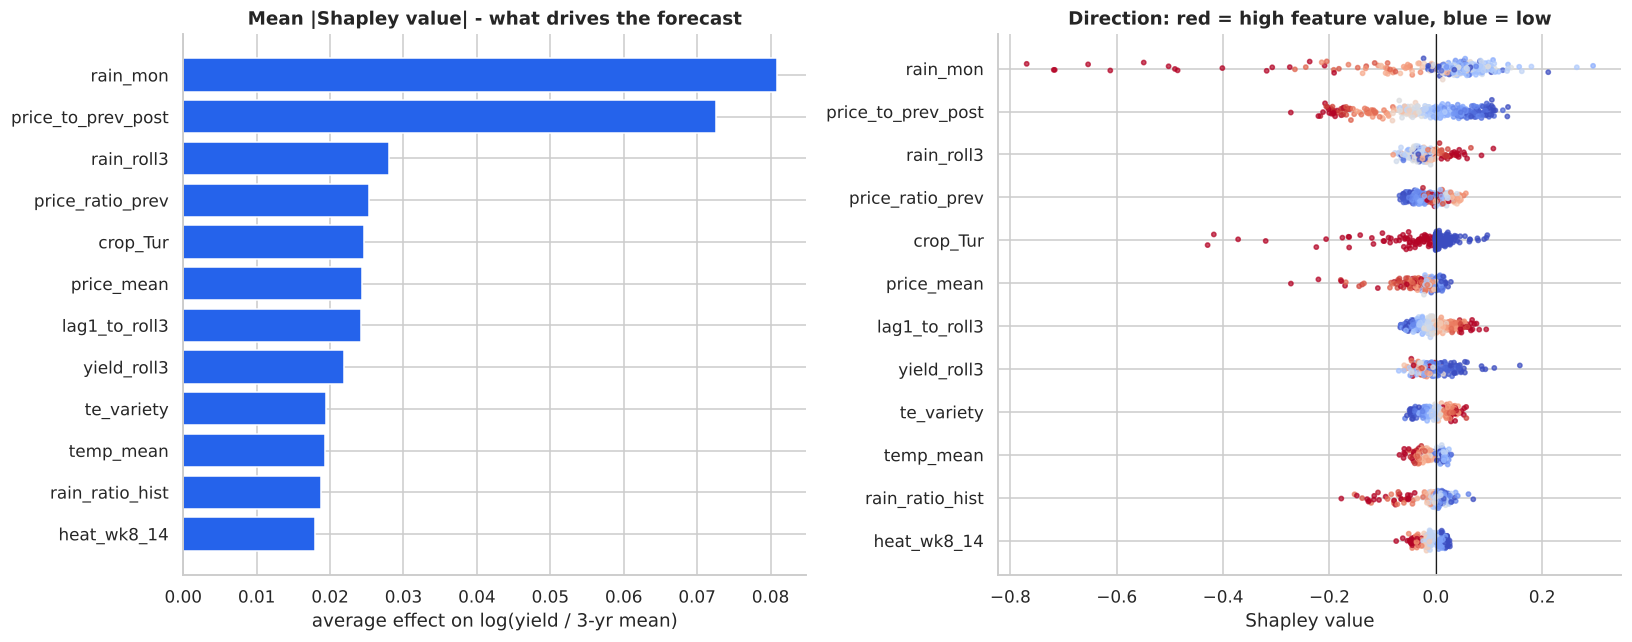

In [21]:
top = imp.head(12).index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].barh(top, imp[top].values, color="#2563eb"); ax[0].set(title="Mean |Shapley value| - what drives the forecast", xlabel="average effect on log(yield / 3-yr mean)")
for k, f in enumerate(top):
    j = FEATS.index(f); v = Xs[f].to_numpy(); lo, hi = np.nanpercentile(v, [5, 95]); c = np.clip((v - lo) / (hi - lo + 1e-9), 0, 1)
    ax[1].scatter(sv[:, j], np.full(len(v), k) + rng.normal(0, .08, len(v)), c=c, cmap="coolwarm", s=8, alpha=.7)
ax[1].set_yticks(range(len(top))); ax[1].set_yticklabels(top); ax[1].axvline(0, color="k", lw=.8)
ax[1].set(title="Direction: red = high feature value, blue = low", xlabel="Shapley value")
plt.tight_layout(); plt.savefig(FIG / "06_shap_summary.png", dpi=130)

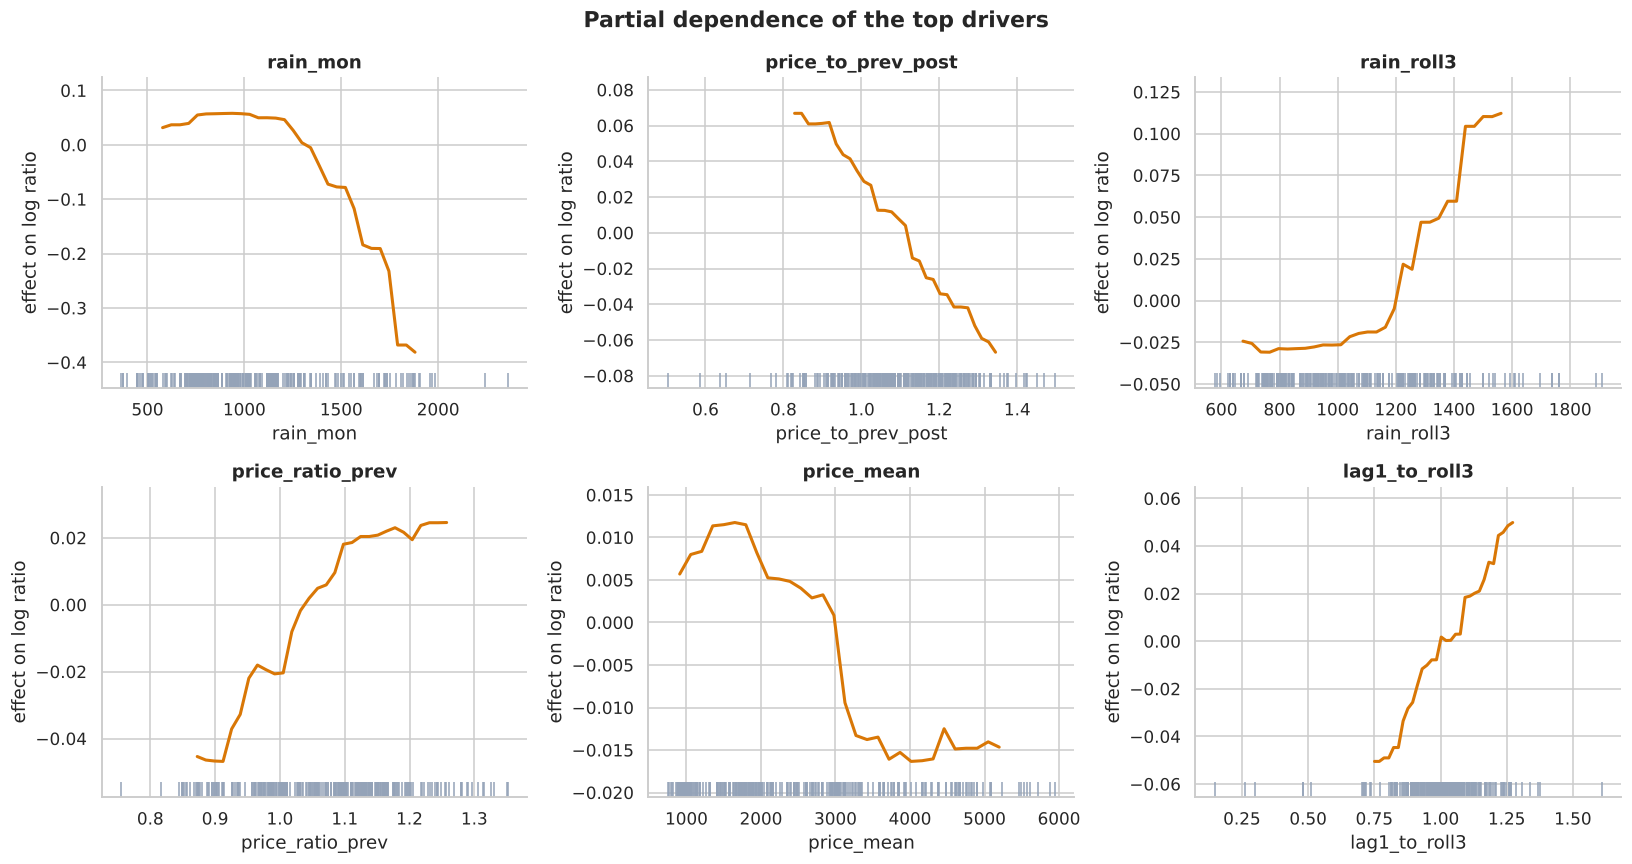

In [22]:
pdp_feats = [f for f in imp.index if f in NUM][:6]
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, f in zip(ax.ravel(), pdp_feats):
    pd_ = partial_dependence(final, Xtr.sample(1500, random_state=SEED), [f], grid_resolution=30)
    a.plot(pd_["grid_values"][0], pd_["average"][0], color="#d97706", lw=2); a.set(title=f, ylabel="effect on log ratio")
    sns.rugplot(Xtr[f].sample(300, random_state=1), ax=a, color="#94a3b8", height=.05)
plt.suptitle("Partial dependence of the top drivers", fontweight="bold"); plt.tight_layout(); plt.savefig(FIG / "07_pdp.png", dpi=130)
RES["pdp_feats"] = pdp_feats

**Do the top drivers make business sense?** The brief asks for a sanity check, so here is the honest read of what the output above shows (numbers are in the printout, not assumed):
- **Rainfall dominates**: monsoon rainfall in weeks 1-17 is the single largest driver, and its 3-year rolling mean (soil-moisture memory) also ranks high. The partial-dependence
  curve is not a straight line: yields fall when the monsoon is far from what the block normally gets, and crops differ in how much wet weather they tolerate. This is what an agronomist expects.
- **Price signals are the second family.** The ratio of this season's early price to *last* harvest's price and the early-season price level matter. Plausible, and
  explainable: last harvest's local price reflects last season's local supply, and rising prices push farmers to invest more in inputs.
  **Caveat:** these features are only valid if mandi prices arrive on time for weeks 1-20; some of their power comes from traders already pricing in crop condition.
- **Yield history** (last year relative to the 3-year norm, block effect, seed variety) adds a smaller but real share.
- **Dry-spell length, soil and heat rank lower than I expected** from the EDA story. They still help, but the data say rainfall *totals and history* explain most of the predictable signal.
- `crop_Tur` appears in the top five because tur is penalised hardest by wet monsoons in this simulated data; this is crop identity acting through rainfall, not an independent cause.

So the top drivers are interpretable and defensible, but the business must understand that price features are market signals, not agronomic causes.

## 12. From forecast to action: which crops and districts to prioritise for procurement
Scenario: forecast issued at week 20 for the **2025 season**, with the model trained only on seasons up to 2024. For each district x crop we compare predicted
supply with the 3-year normal and look at early-season price momentum (rising prices = competition for scarce grain).

hindsight check (2025 actuals now known): rank correlation predicted vs actual supply change = 0.75; direction (shortfall vs surplus) correct in 75% of 36 district-crop pairs


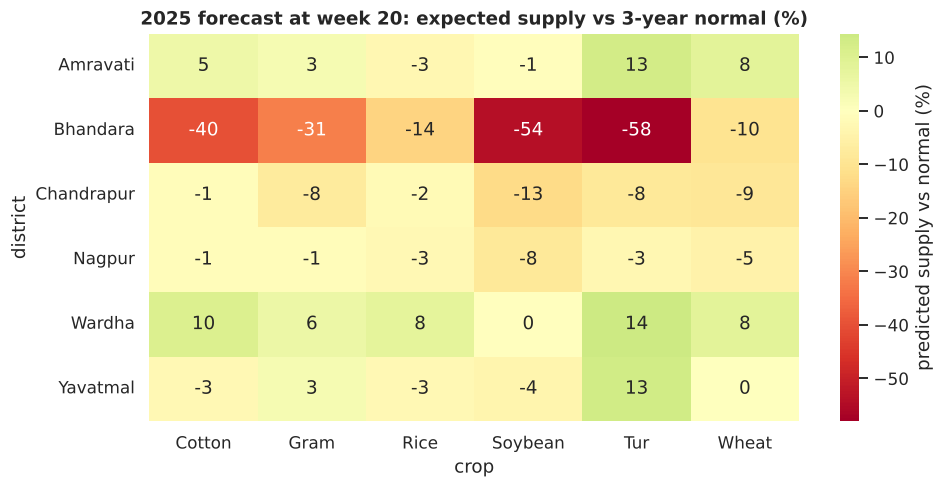

In [23]:
fin24 = clone(gb).fit(M[M.ag_year <= 2024][FEATS], M[M.ag_year <= 2024].y)
cur = M[M.ag_year == 2025].copy(); cur["pred_ratio"] = fin24.predict(cur[FEATS])
cur["pred_yield"] = cur.yield_roll3 * np.exp(cur.pred_ratio); cur["normal_prod_t"] = cur.yield_roll3 * cur.area_ha / 10; cur["actual_prod_t"] = cur.yield_qha * cur.area_ha / 10; cur["pred_prod_t"] = cur.pred_yield * cur.area_ha / 10
act = cur.groupby(["district", "crop"]).agg(pred_prod_t=("pred_prod_t", "sum"), normal_prod_t=("normal_prod_t", "sum"), actual_prod_t=("actual_prod_t", "sum"), price_mom=("price_mom", "mean"),
                                           actual_yield=("yield_qha", "mean"), pred_yield=("pred_yield", "mean")).reset_index()
act["supply_vs_normal_%"] = 100 * (act.pred_prod_t / act.normal_prod_t - 1)
act["price_momentum_%"] = 100 * (act.price_mom - 1)
act["actual_supply_vs_normal_%"] = 100 * (act.actual_prod_t / act.normal_prod_t - 1)
act["priority_score"] = -act["supply_vs_normal_%"] + 0.5 * act["price_momentum_%"]
def advice(r):
    if r["supply_vs_normal_%"] <= -4: return "BOOK EARLY: forward contracts / farm-gate buying"
    if r["supply_vs_normal_%"] >= 4: return "WAIT: buy spot, expect softer prices"
    return "ROUTINE: normal procurement plan"
act["action"] = act.apply(advice, axis=1)
from scipy.stats import spearmanr
rho = spearmanr(act["supply_vs_normal_%"], act["actual_supply_vs_normal_%"])[0]
sign_hit = float(((act["supply_vs_normal_%"] < 0) == (act["actual_supply_vs_normal_%"] < 0)).mean())
print(f"hindsight check (2025 actuals now known): rank correlation predicted vs actual supply change = {rho:.2f}; direction (shortfall vs surplus) correct in {sign_hit:.0%} of 36 district-crop pairs")
RES["hindsight"] = {"rho": float(rho), "direction_hit": sign_hit}
act = act.sort_values("priority_score", ascending=False).reset_index(drop=True)

RES["actions_top"] = act.head(8)[["district", "crop", "supply_vs_normal_%", "actual_supply_vs_normal_%", "price_momentum_%", "action"]].round(1).to_dict("records")
RES["actions_counts"] = act.action.value_counts().to_dict()
piv_a = act.pivot(index="district", columns="crop", values="supply_vs_normal_%")
fig, ax = plt.subplots(figsize=(9, 4.6)); sns.heatmap(piv_a, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "predicted supply vs normal (%)"})
ax.set(title="2025 forecast at week 20: expected supply vs 3-year normal (%)"); plt.tight_layout(); plt.savefig(FIG / "08_procurement_heatmap.png", dpi=130)

## 13. Stretch: fairness and stability across regions and customer groups, plus recalibration
Checks on the test years: error and **bias** (signed) by district, by crop, and by farm-size group (small / medium / large sown area = proxy for customer groups);
drift of input distributions (population stability index); then an online **residual recalibration**: the previous season's bias per district x crop is known
at the next forecast date, so half of it is added back (shrunk to avoid chasing noise).

In [24]:
f = to_level(te, pt); f["ratio_err"] = np.log(f.pred / f.yield_qha); f["abs_err"] = (f.pred - f.yield_qha).abs(); f["pct_err"] = 100 * f.abs_err / f.yield_qha
f["size_group"] = pd.qcut(te.area_ha.values, 3, labels=["small", "medium", "large"])
fair = {}
for col in ["district", "crop", "size_group"]:
    t_ = f.groupby(col).agg(MAE_qha=("abs_err", "mean"), MAPE_pct=("pct_err", "mean"), bias_pct=("ratio_err", lambda s: 100 * s.mean())).round(2)
    fair[col] = t_; print(f"\nBy {col}:\n{t_.to_string()}")
RES["fair"] = {k: v.reset_index().to_dict("records") for k, v in fair.items()}
cc = f[(f.district == "Chandrapur") & f.crop.isin(["Wheat", "Gram", "Rice"])]
print(f"\nChandrapur wheat/gram/rice bias in test: {100 * cc.ratio_err.mean():+.1f}% (negative = under-prediction) vs all others {100 * f[~f.index.isin(cc.index)].ratio_err.mean():+.1f}%")
def psi(a, b, bins=10):
    q = np.nanquantile(a, np.linspace(0, 1, bins + 1)); q[0], q[-1] = -np.inf, np.inf
    pa, pb = np.histogram(a[~np.isnan(a)], q)[0] / a.notna().sum(), np.histogram(b[~np.isnan(b)], q)[0] / b.notna().sum()
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None); return float(np.sum((pb - pa) * np.log(pb / pa)))
ps = pd.Series({c: psi(tr[c], te[c]) for c in ["rain_mon", "rain_ratio_hist", "dry_run_wk5_14", "soil_oc", "price_mom", "price_ratio_prev", "lag1_to_roll3", "yield_roll3"]}).sort_values(ascending=False)
print("\nPSI train -> test (>0.25 = major shift):\n", ps.round(3).to_string()); RES["psi"] = ps.round(3).to_dict()


By district:
            MAE_qha  MAPE_pct  bias_pct
district                               
Amravati       1.66      8.85     -4.19
Bhandara       2.46     14.81     -7.87
Chandrapur     1.78      8.72      0.64
Nagpur         1.61      9.74     -4.97
Wardha         1.68     10.46     -3.31
Yavatmal       1.47     10.81      1.29

By crop:
         MAE_qha  MAPE_pct  bias_pct
crop                                
Cotton      0.89      9.58     -3.67
Gram        1.45     11.54     -6.63
Rice        2.49      9.17      0.17
Soybean     1.25     11.24     -2.17
Tur         0.66      9.53     -1.10
Wheat       3.88     12.29     -5.04

By size_group:
            MAE_qha  MAPE_pct  bias_pct
size_group                             
small          1.81     10.74     -3.30
medium         1.80     10.86     -3.44
large          1.71     10.09     -2.48

Chandrapur wheat/gram/rice bias in test: -2.1% (negative = under-prediction) vs all others -3.2%

PSI train -> test (>0.25 = major shift):
 pri

2024-25 MAE_district  raw: 1.105 | recalibrated: 1.287
Chandrapur MAE        raw: 0.897 | recalibrated: 1.3


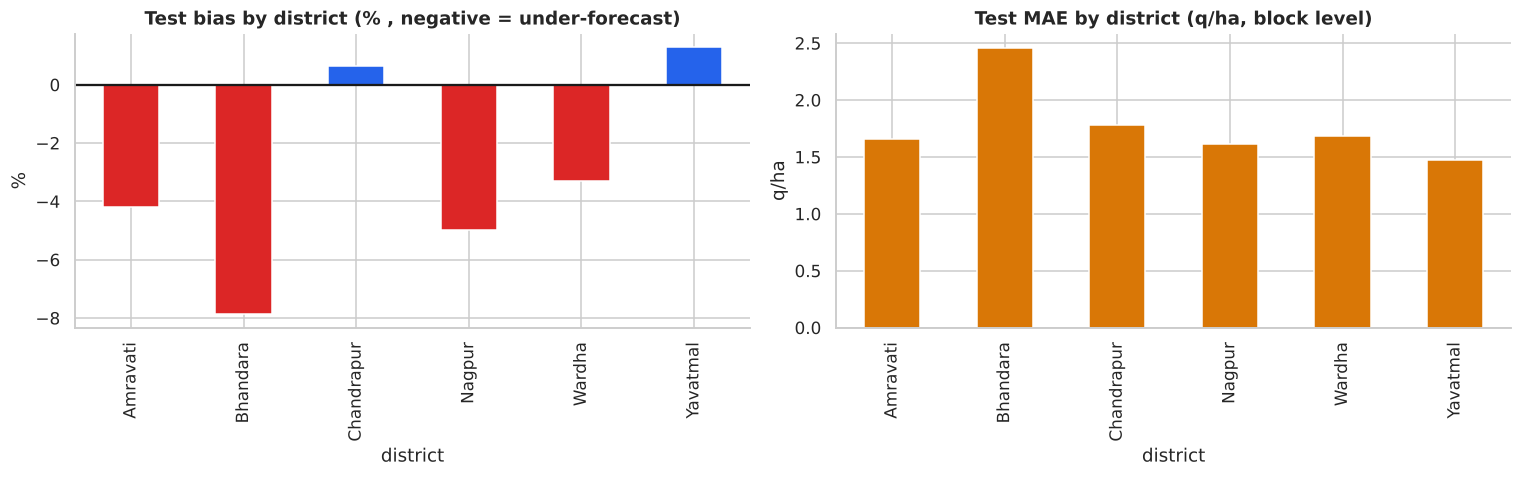

In [25]:
# online recalibration for 2024 and 2025: offset = 0.5 x mean log residual of the PREVIOUS season at that district x crop (known by then)
f2 = f.copy(); f2["resid_log"] = np.log(f2.yield_qha / f2.pred)                       # +ve = under-predicted
off = f2.groupby(["district", "crop", "ag_year"]).resid_log.mean().rename("off").reset_index(); off["ag_year"] += 1
f2 = f2.merge(off, on=["district", "crop", "ag_year"], how="left")
use = f2[f2.ag_year >= 2024].copy(); use["pred_cal"] = use.pred * np.exp(0.5 * use.off.fillna(0))
d_raw, d_cal = use.assign(p=use.pred).groupby(["district", "crop", "ag_year"]).agg(a=("yield_qha", "mean"), p=("p", "mean")).reset_index(), \
               use.groupby(["district", "crop", "ag_year"]).agg(a=("yield_qha", "mean"), p=("pred_cal", "mean")).reset_index()
print("2024-25 MAE_district  raw:", round(mae(d_raw.a, d_raw.p), 3), "| recalibrated:", round(mae(d_cal.a, d_cal.p), 3))
chd = lambda d: d[d.district == "Chandrapur"]
print("Chandrapur MAE        raw:", round(mae(chd(d_raw).a, chd(d_raw).p), 3), "| recalibrated:", round(mae(chd(d_cal).a, chd(d_cal).p), 3))
RES["recal"] = {"raw": mae(d_raw.a, d_raw.p), "cal": mae(d_cal.a, d_cal.p), "chd_raw": mae(chd(d_raw).a, chd(d_raw).p), "chd_cal": mae(chd(d_cal).a, chd(d_cal).p)}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
fair["district"].bias_pct.plot.bar(ax=ax[0], color=["#dc2626" if abs(v) > 3 else "#2563eb" for v in fair["district"].bias_pct]); ax[0].axhline(0, color="k"); ax[0].set(title="Test bias by district (% , negative = under-forecast)", ylabel="%")
fair["district"].MAE_qha.plot.bar(ax=ax[1], color="#d97706"); ax[1].set(title="Test MAE by district (q/ha, block level)", ylabel="q/ha")
plt.tight_layout(); plt.savefig(FIG / "09_fairness_by_district.png", dpi=130)

**Reading section 13.** Three honest findings:
1. **Fairness across farm size is fine** (small / medium / large groups have similar error and bias).
2. **The weak spot is weather regime and region, not farm size**: Bhandara has the highest error and an under-forecast bias, because the model over-predicts yield collapses in unusually wet seasons there (section 9b).
3. **The simple recalibration did not help**: adding half of last season's district-crop residual made forecasts *worse*, including for Chandrapur. One season of residual is mostly weather noise
   shared across blocks, not a stable bias, and annual retraining already absorbs the Chandrapur drift (its test bias is small). I would **not** ship this recalibration; a better option is
   a multi-season, significance-tested correction, or a wider uncertainty band for out-of-range monsoons.

## 14. Be ready to explain one wrong prediction
Pick the test-year block-crop with the largest percentage error, explain the forecast with its own Shapley values, and test two hypotheses: (a) the monsoon was
unusual relative to the block's history, (b) something happened after the week-20 cutoff that the model could never see.

WRD-Block-8 | Soybean | 2023: predicted 15.2 q/ha vs actual 9.9 q/ha (+53%)  | 3-yr normal 15.6

top contributions to this forecast (log-ratio units; base value 0.015 ):
price_to_prev_post    0.059
price_mom             0.042
yield_roll3          -0.037
price_ratio_prev     -0.034
rain_roll3           -0.031
temp_mean            -0.022

rainfall weeks 1-17 this season: 1332 mm  (this block's earlier seasons: median 811, max 2098) -> higher than 88% of its history
3-year rolling baseline = 15.6 q/ha, but the block's last 3 yields were [13.6, 18.6, 14.8]: one very good season lifted the baseline
relative wetness of this season = 1.44x the block's own history. In 2006-2022, Soybean seasons with similar relative wetness (63 rows) realised on average 0.69 x their 3-year baseline, and this one realised 0.63 x; the model predicted 0.97 x
Shapley contribution of the rainfall features to this forecast: {'rain_mon': -0.006, 'rain_ratio_hist': -0.004, 'rain_ratio_hist_sq': -0.002, 'rain_roll3': -

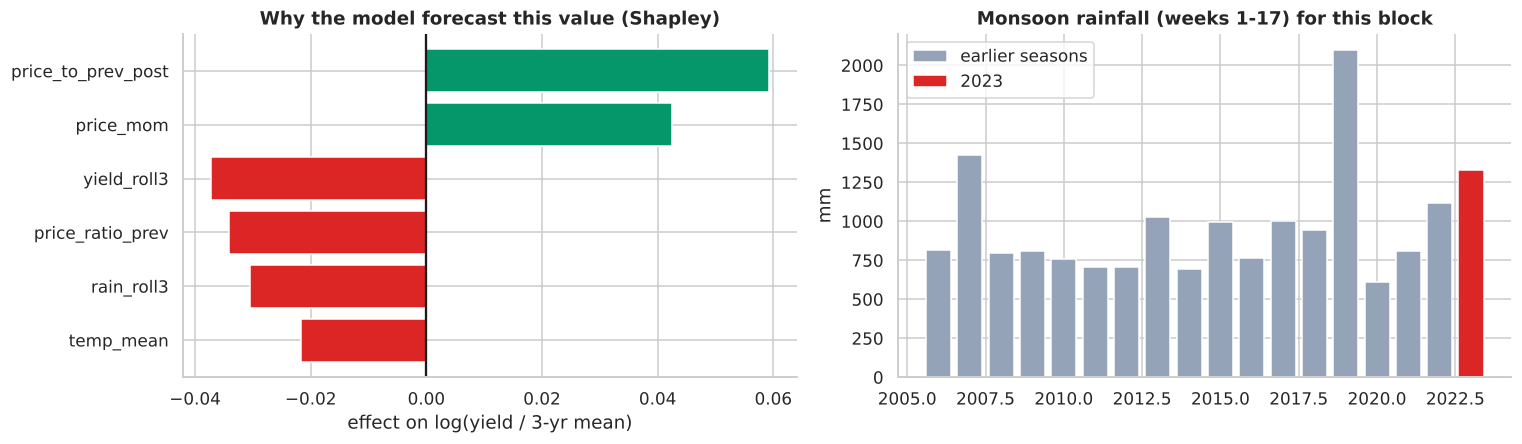

In [26]:
wr = te.copy(); wr["pred"] = wr.yield_roll3 * np.exp(pt); wr["pct"] = 100 * (wr.pred / wr.yield_qha - 1); worst = wr.loc[wr.pct.abs().idxmax()]
print(f"{worst.block} | {worst.crop} | {int(worst.ag_year)}: predicted {worst.pred:.1f} q/ha vs actual {worst.yield_qha:.1f} q/ha ({worst.pct:+.0f}%)  | 3-yr normal {worst.yield_roll3:.1f}")
x1 = worst[FEATS].astype(float).to_frame().T
def pred1(Z): return final.predict(pd.DataFrame(Z, columns=FEATS))
phi = np.zeros(len(FEATS)); Xn = x1.to_numpy()[0]
for _ in range(200):
    perm = rng.permutation(len(FEATS)); b = bg[rng.integers(len(bg))]; Z = np.tile(b, (len(FEATS) + 1, 1))
    for j, ft in enumerate(perm): Z[j + 1:, ft] = Xn[ft]
    phi[perm] += np.diff(pred1(Z))
phi /= 200; base_val = float(pred1(bg).mean())
contrib = pd.Series(phi, index=FEATS).reindex(pd.Series(phi, index=FEATS).abs().sort_values(ascending=False).index).head(6)
print("\ntop contributions to this forecast (log-ratio units; base value", round(base_val, 3), "):"); print(contrib.round(3).to_string())
hist_b = M[(M.block == worst.block) & (M.crop == worst.crop) & (M.ag_year < worst.ag_year)]
rain_pct = float((hist_b.rain_mon < worst.rain_mon).mean() * 100)
oor = worst.rain_mon > hist_b.rain_mon.max()
analog = M[(M.ag_year <= 2022) & (M.crop == worst.crop) & (M.rain_ratio_hist.between(0.9 * worst.rain_ratio_hist, 1.1 * worst.rain_ratio_hist))]
an_ratio = float(np.exp(analog.y.mean())) if len(analog) else np.nan
print(f"\nrainfall weeks 1-17 this season: {worst.rain_mon:.0f} mm  (this block's earlier seasons: median {hist_b.rain_mon.median():.0f}, max {hist_b.rain_mon.max():.0f}) -> higher than {rain_pct:.0f}% of its history")
print(f"3-year rolling baseline = {worst.yield_roll3:.1f} q/ha, but the block's last 3 yields were {list(hist_b.yield_qha.tail(3).round(1))}: one very good season lifted the baseline")
print(f"relative wetness of this season = {worst.rain_ratio_hist:.2f}x the block's own history. In 2006-2022, {worst.crop} seasons with similar relative wetness ({len(analog)} rows) realised on average {an_ratio:.2f} x their 3-year baseline, and this one realised {worst.yield_qha / worst.yield_roll3:.2f} x; the model predicted {np.exp(pt[te.index.get_loc(worst.name)]):.2f} x")
print("Shapley contribution of the rainfall features to this forecast:", {k_: round(float(v_), 3) for k_, v_ in pd.Series(phi, index=FEATS)[["rain_mon", "rain_ratio_hist", "rain_ratio_hist_sq", "rain_roll3"]].items()})
sel = df[(df.block == worst.block) & (df.crop == worst.crop) & (df.ag_year == worst.ag_year)]
late_rain = sel[sel.week_no.between(21, 40)].rain.sum()
late_rain_hist = df[(df.block == worst.block) & (df.crop == worst.crop) & (df.ag_year < worst.ag_year) & df.week_no.between(21, 40)].groupby("ag_year").rain.sum().mean()
heat_late = int((sel[sel.week_no.between(30, 38)].temp_max_c > 33).sum())
print(f"post-cutoff check (not the cause here): rain weeks 21-40 = {late_rain:.0f} mm vs past mean {late_rain_hist:.0f}; hot weeks 30-38 = {heat_late}")
RES["wrong"] = {"block": worst.block, "crop": worst.crop, "year": int(worst.ag_year), "pred": float(worst.pred), "actual": float(worst.yield_qha), "pct": float(worst.pct),
                "normal": float(worst.yield_roll3), "contrib": contrib.round(3).to_dict(), "district": worst.district, "rain": float(worst.rain_mon),
                "rain_hist_median": float(hist_b.rain_median if False else hist_b.rain_mon.median()), "rain_hist_max": float(hist_b.rain_mon.max()), "rain_pct": rain_pct,
                "last3": [float(v) for v in hist_b.yield_qha.tail(3)], "analog_ratio": an_ratio, "actual_ratio": float(worst.yield_qha / worst.yield_roll3), "rel_wet": float(worst.rain_ratio_hist), "analog_n": int(len(analog)), "model_ratio": float(np.exp(pt[te.index.get_loc(worst.name)])),
                "late_rain": float(late_rain), "late_rain_hist": float(late_rain_hist), "heat_late": heat_late}
sel_w = wr.groupby(["crop"]).apply(lambda d: 100 * (d.pred / d.yield_qha - 1).abs().mean()).round(1)
print("\nmean absolute % error by crop (test):", sel_w.to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].barh(contrib.index[::-1], contrib.values[::-1], color=["#dc2626" if v < 0 else "#059669" for v in contrib.values[::-1]]); ax[0].axvline(0, color="k"); ax[0].set(title="Why the model forecast this value (Shapley)", xlabel="effect on log(yield / 3-yr mean)")
ax[1].bar(hist_b.ag_year, hist_b.rain_mon, color="#94a3b8", label="earlier seasons"); ax[1].bar([worst.ag_year], [worst.rain_mon], color="#dc2626", label=str(int(worst.ag_year)))
ax[1].set(title="Monsoon rainfall (weeks 1-17) for this block", ylabel="mm"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "10_wrong_prediction.png", dpi=130)

## 15. Save deliverables
Trained model, test predictions, metrics, and the data needed by the model card and findings deck.

In [27]:
joblib.dump({"model": final, "features": FEATS, "cutoff_week": CUTOFF, "target": "log(yield_q_ha / 3-yr block-crop rolling mean)", "trained_on": "2006-2022",
             "best_params": RES["best_params"], "created": "2026-11"}, MODELS / "yield_model.joblib")
out = f[["district", "block", "crop", "ag_year", "yield_qha", "pred", "yield_roll3"]].rename(columns={"yield_qha": "actual", "pred": "predicted", "yield_roll3": "baseline_3yr"})
out.to_csv(REPORTS / "test_predictions.csv", index=False)
M[["district", "block", "crop", "ag_year", "yield_qha"] + FEATS].to_csv(ROOT / "data/processed/model_table.csv.gz", index=False, compression="gzip")
RES["by_crop_test_mape"] = sel_w.to_dict()
RES["n_season_rows"] = int(len(M))
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)): return int(o)
    return o
json.dump(clean(RES), open(REPORTS / "metrics.json", "w"), indent=2)
print("saved: model, predictions, model table, metrics.json")
print(json.dumps(clean({k: RES[k] for k in ["final", "shortfall", "recal"]}), indent=1)[:2500])

saved: model, predictions, model table, metrics.json
{
 "final": {
  "val": {
   "MAE_block": 1.6230380420770565,
   "MAE_district": 0.8494546070448356,
   "WAPE_district_%": 5.030525366811157
  },
  "test": {
   "MAE_block": 1.775277609465307,
   "MAE_district": 1.1871779731108176,
   "WAPE_district_%": 7.197802670714852
  },
  "val_base": {
   "MAE_block": 2.106455015104994,
   "MAE_district": 1.4653460239180371,
   "WAPE_district_%": 8.677874348248109
  },
  "test_base": {
   "MAE_block": 2.3909629206549816,
   "MAE_district": 1.7212382582804604,
   "WAPE_district_%": 10.43578436679031
  },
  "imp_val": 42.03044242249576,
  "imp_test": 31.027679207129406,
  "gap_test_vs_val_pct": 39.757670776651224
 },
 "shortfall": {
  "val_recall": 0.6111111111111112,
  "val_precision": 0.7333333333333333,
  "val_n": 18,
  "test_recall": 0.8214285714285714,
  "test_precision": 0.6052631578947368,
  "test_n": 28
 },
 "recal": {
  "raw": 1.1047431812333919,
  "cal": 1.2868182527410552,
  "chd_raw": 